### Practica de Dataset Churn Clientes (Mineria de Datos)

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import metrics
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier

In [31]:
df = pd.read_csv("../Churn-Clientes.csv")

In [32]:
print(len(df))
df = df.dropna()
print(len(df))

440833
440832


In [33]:
df = df.drop(columns=["ID"])

df['Genero'] = df['Genero'].map({'Male': 1, 'Female': 0})
df['TipoSuscripcion'] = df['TipoSuscripcion'].map({'Basic': 0, 'Standard': 1, 'Premium': 2})
df['DuracionContrato'] = df['DuracionContrato'].map({'Monthly': 0, 'Quarterly': 1, 'Annual': 2})

In [34]:
df = df.select_dtypes(include=[np.number])
df.columns = df.columns.str.strip()
matriz_correlacion = df.corr()
caracteristicas_alta_correlacion = [(col1, col2, matriz_correlacion.loc[col1,col2])
                                   for col1 in matriz_correlacion.columns
                                   for col2 in matriz_correlacion.columns
                                   if col1 != col2 and abs(matriz_correlacion.loc[col1,col2])>0.8]
multicolinealidad_df = pd.DataFrame(caracteristicas_alta_correlacion, columns = ["Caracteristica 1","Caracteristica 2","Correlacion"])
print("?\nCaracteristicas altamente correlacionadas:\n", multicolinealidad_df)

?
Caracteristicas altamente correlacionadas:
 Empty DataFrame
Columns: [Caracteristica 1, Caracteristica 2, Correlacion]
Index: []


In [35]:
df2 = df
df2 = df2.drop(columns=["Fuga"])
vif_df = pd.DataFrame()
vif_df.head
vif_df["Caracteristica"]  = df2.columns 
vif_df["VIF"] = [variance_inflation_factor(df2.values, i) for i in range(df2.shape[1])]
print("\nFactor de Inflacion de Varianza (VIF) para cada caracteristica:\n",vif_df)


Factor de Inflacion de Varianza (VIF) para cada caracteristica:
       Caracteristica       VIF
0               Edad  8.398071
1             Genero  2.345546
2           Tenencia  3.890970
3      FrecuenciaUso  3.995877
4    LlamadasSoporte  2.546157
5        RetrasoPago  3.345774
6    TipoSuscripcion  2.442616
7   DuracionContrato  3.483745
8         GastoTotal  6.486753
9  UltimaInteraccion  3.719664


In [36]:
y = df["Fuga"]
X = df.drop(columns=["Fuga"])

In [37]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [38]:
modelo = LogisticRegression(random_state=16, max_iter=1000)
modelo.fit(X_train, y_train)

C:\Users\gipsy\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,16
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


Text(0.5, 427.9555555555555, 'Prediccion')

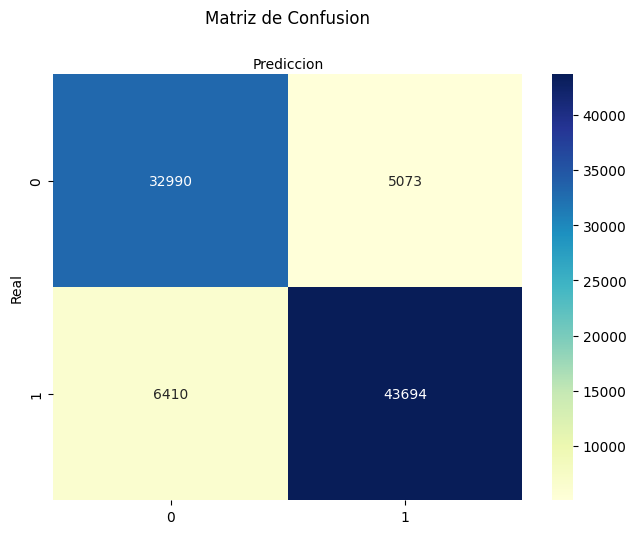

In [39]:
y_pred = modelo.predict(X_test)

matriz_confusion = metrics.confusion_matrix(y_test, y_pred)

nombres_clases=[0,1]
fig, ax = plt.subplots()
marcas_verificacion = np.arange(len(nombres_clases))
plt.xticks(marcas_verificacion, nombres_clases)
plt.yticks(marcas_verificacion, nombres_clases)

sns.heatmap(pd.DataFrame(matriz_confusion), annot=True, cmap="YlGnBu", fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Matriz de Confusion', y=1.1)
plt.ylabel('Real')
plt.xlabel('Prediccion')

In [40]:
y_pred = y_pred.astype(int)
#(True Positive + True Negative) / Total Predictions
Accuracy =metrics.accuracy_score(y_test, y_pred)
#True Positive / (True Positive + False Positive)
Precision = metrics.precision_score(y_test, y_pred)
#True Positive / (True Positive + False Negative)
Sensitivity_recall = metrics.recall_score(y_test, y_pred)
#True Negative / (True Negative + False Positive)
Specificity = metrics.recall_score(y_test, y_pred, pos_label=0)
#2 * ((Precision * Sensitivity) / (Precision + Sensitivity))
F1_score = metrics.f1_score(y_test, y_pred)
print({"Exactitud":Accuracy,"Precision":Precision,
      "Sensibilidad_recall":Sensitivity_recall,
      "Especificidad":Specificity,"F1_score":F1_score})

{'Exactitud': 0.8697585264327923, 'Precision': 0.8959747370147846, 'Sensibilidad_recall': 0.8720661025067858, 'Especificidad': 0.8667209626146126, 'F1_score': 0.8838587654620668}


In [41]:
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


Text(0.5, 427.9555555555555, 'Prediccion')

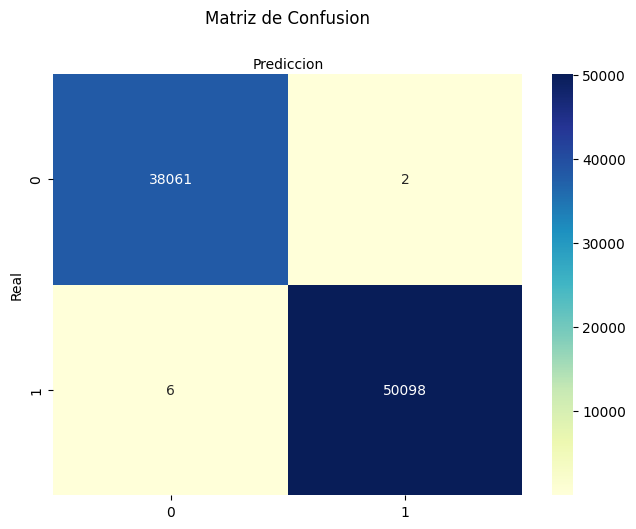

In [42]:
y_pred = model.predict(X_test)

matriz_confusion = metrics.confusion_matrix(y_test, y_pred)

nombres_clases=[0,1]
fig, ax = plt.subplots()
marcas_verificacion = np.arange(len(nombres_clases))
plt.xticks(marcas_verificacion, nombres_clases)
plt.yticks(marcas_verificacion, nombres_clases)

sns.heatmap(pd.DataFrame(matriz_confusion), annot=True, cmap="YlGnBu", fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Matriz de Confusion', y=1.1)
plt.ylabel('Real')
plt.xlabel('Prediccion')

In [43]:
y_pred = y_pred.astype(int)
#(True Positive + True Negative) / Total Predictions
Accuracy =metrics.accuracy_score(y_test, y_pred)
#True Positive / (True Positive + False Positive)
Precision = metrics.precision_score(y_test, y_pred)
#True Positive / (True Positive + False Negative)
Sensitivity_recall = metrics.recall_score(y_test, y_pred)
#True Negative / (True Negative + False Positive)
Specificity = metrics.recall_score(y_test, y_pred, pos_label=0)
#2 * ((Precision * Sensitivity) / (Precision + Sensitivity))
F1_score = metrics.f1_score(y_test, y_pred)
print({"Exactitud":Accuracy,"Precision":Precision,
      "Sensibilidad_recall":Sensitivity_recall,
      "Especificidad":Specificity,"F1_score":F1_score})

{'Exactitud': 0.999909263102975, 'Precision': 0.9999600798403193, 'Sensibilidad_recall': 0.9998802490819096, 'Especificidad': 0.9999474555342459, 'F1_score': 0.9999201628677498}


In [44]:
print(model.feature_importances_)

[0.14346623 0.03435449 0.00917986 0.0029348  0.30483095 0.12255967
 0.00121175 0.13537697 0.21227876 0.03380652]
